Iteration: 1 Best MSE: 0.121428
Iteration: 2 Best MSE: 0.121428
Iteration: 3 Best MSE: 0.121428
Iteration: 4 Best MSE: 0.121428
Iteration: 5 Best MSE: 0.121428
Iteration: 6 Best MSE: 0.121428
Iteration: 7 Best MSE: 0.121428
Iteration: 8 Best MSE: 0.121428
Iteration: 9 Best MSE: 0.121428
Iteration: 10 Best MSE: 0.042281
Iteration: 11 Best MSE: 0.042281
Iteration: 12 Best MSE: 0.042281
Iteration: 13 Best MSE: 0.042281
Iteration: 14 Best MSE: 0.024781
Iteration: 15 Best MSE: 0.0247
Iteration: 16 Best MSE: 0.016438
Iteration: 17 Best MSE: 0.016438
Iteration: 18 Best MSE: 0.01397
Iteration: 19 Best MSE: 0.01397
Iteration: 20 Best MSE: 0.010498
Iteration: 21 Best MSE: 0.010498
Iteration: 22 Best MSE: 0.008237
Iteration: 23 Best MSE: 0.008237
Iteration: 24 Best MSE: 0.007696
Iteration: 25 Best MSE: 0.007672
Iteration: 26 Best MSE: 0.007672
Iteration: 27 Best MSE: 0.007013
Iteration: 28 Best MSE: 0.00564
Iteration: 29 Best MSE: 0.004768
Iteration: 30 Best MSE: 0.00456
Iteration: 31 Best MSE: 0

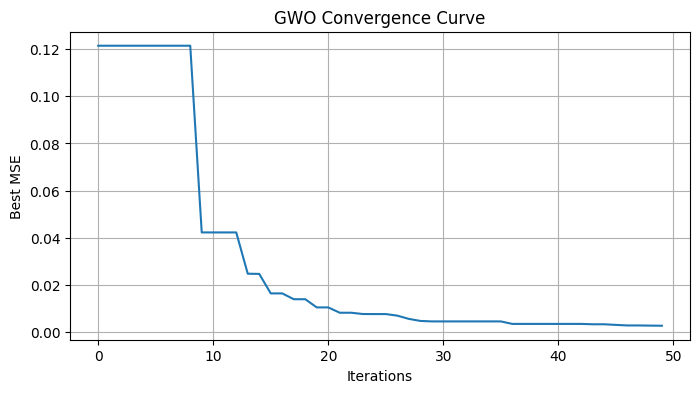

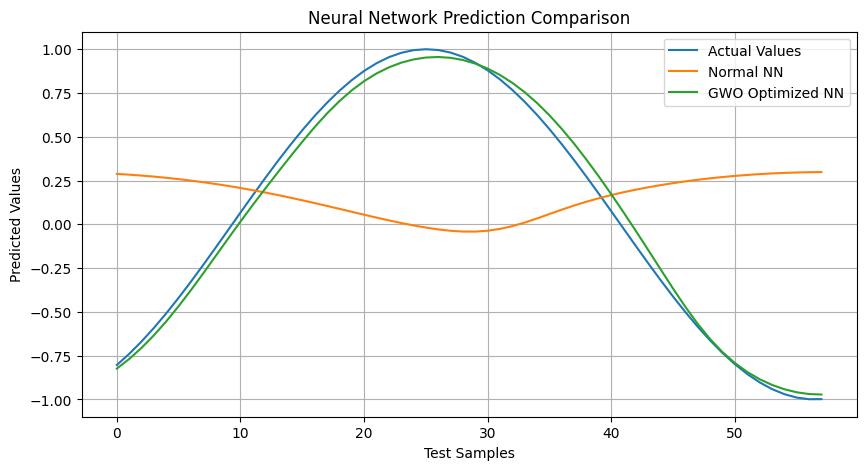

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# -----------------------------------
# 1. Generate Dataset
# -----------------------------------

np.random.seed(42)

data = np.sin(np.arange(0, 30, 0.1))

window_size = 10
X = []
Y = []

for i in range(len(data) - window_size):
    X.append(data[i:i + window_size])
    Y.append(data[i + window_size])

X = np.array(X)
Y = np.array(Y)

# Split dataset into training and testing
split = int(0.8 * len(X))

X_train = X[:split]
Y_train = Y[:split]

X_test = X[split:]
Y_test = Y[split:]

# -----------------------------------
# 2. Initialize Neural Network
# -----------------------------------

hidden_size = 5

# Total number of weights and biases
dimension = (
    hidden_size +
    hidden_size * hidden_size +
    hidden_size +
    hidden_size +
    1
)

# -----------------------------------
# 3. Extract Neural Network Parameters
# -----------------------------------

def get_parameters(position):

    index = 0

    Wx = position[index:index + hidden_size].reshape(hidden_size, 1)
    index += hidden_size

    Wh = position[index:index + hidden_size * hidden_size].reshape(
        hidden_size, hidden_size
    )
    index += hidden_size * hidden_size

    bh = position[index:index + hidden_size]
    index += hidden_size

    Wy = position[index:index + hidden_size]
    index += hidden_size

    by = position[index]

    return Wx, Wh, bh, Wy, by


# -----------------------------------
# 4. Elman Neural Network
# -----------------------------------

def predict(position, X):

    Wx, Wh, bh, Wy, by = get_parameters(position)

    hidden = np.zeros((len(X), hidden_size))

    for t in range(X.shape[1]):

        current_input = X[:, t].reshape(-1, 1)

        hidden = np.tanh(
            current_input @ Wx.T +
            hidden @ Wh.T +
            bh
        )

    output = hidden @ Wy + by

    return output


# -----------------------------------
# 5. Fitness Function (MSE)
# -----------------------------------

def fitness(position):

    predictions = predict(position, X_train)

    mse = np.mean((Y_train - predictions) ** 2)

    return mse


# -----------------------------------
# 6. Grey Wolf Optimizer
# -----------------------------------

def GWO():

    wolves = 20
    iterations = 50

    lower_bound = -1
    upper_bound = 1

    # Initialize wolf positions
    positions = np.random.uniform(
        lower_bound, upper_bound,
        (wolves, dimension)
    )

    alpha = np.zeros(dimension)
    beta = np.zeros(dimension)
    delta = np.zeros(dimension)

    alpha_score = float('inf')
    beta_score = float('inf')
    delta_score = float('inf')

    convergence = []

    for iteration in range(iterations):

        # Evaluate fitness
        for i in range(wolves):

            score = fitness(positions[i])

            if score < alpha_score:

                delta_score = beta_score
                delta = beta.copy()

                beta_score = alpha_score
                beta = alpha.copy()

                alpha_score = score
                alpha = positions[i].copy()

            elif score < beta_score:

                delta_score = beta_score
                delta = beta.copy()

                beta_score = score
                beta = positions[i].copy()

            elif score < delta_score:

                delta_score = score
                delta = positions[i].copy()

        # Parameter a decreases from 2 to 0
        a = 2 - 2 * iteration / iterations

        # Update positions of wolves
        for i in range(wolves):

            r1 = np.random.random(dimension)
            r2 = np.random.random(dimension)

            A1 = 2 * a * r1 - a
            C1 = 2 * r2

            D_alpha = np.abs(C1 * alpha - positions[i])
            X1 = alpha - A1 * D_alpha

            r1 = np.random.random(dimension)
            r2 = np.random.random(dimension)

            A2 = 2 * a * r1 - a
            C2 = 2 * r2

            D_beta = np.abs(C2 * beta - positions[i])
            X2 = beta - A2 * D_beta

            r1 = np.random.random(dimension)
            r2 = np.random.random(dimension)

            A3 = 2 * a * r1 - a
            C3 = 2 * r2

            D_delta = np.abs(C3 * delta - positions[i])
            X3 = delta - A3 * D_delta

            # Update wolf position
            positions[i] = (X1 + X2 + X3) / 3

            positions[i] = np.clip(
                positions[i], lower_bound, upper_bound
            )

        convergence.append(alpha_score)

        print(
            "Iteration:", iteration + 1,
            "Best MSE:", round(alpha_score, 6)
        )

    return alpha, convergence


# -----------------------------------
# 7. Normal Neural Network
# -----------------------------------

normal_weights = np.random.uniform(
    -0.5, 0.5, dimension
)

normal_train_mse = fitness(normal_weights)

normal_test_predictions = predict(normal_weights, X_test)

normal_test_mse = np.mean(
    (Y_test - normal_test_predictions) ** 2
)


# -----------------------------------
# 8. Apply GWO Optimization
# -----------------------------------

best_weights, convergence = GWO()

optimized_train_mse = fitness(best_weights)

optimized_test_predictions = predict(best_weights, X_test)

optimized_test_mse = np.mean(
    (Y_test - optimized_test_predictions) ** 2
)


# -----------------------------------
# 9. Display Results
# -----------------------------------

print("\n----------- FINAL RESULTS -----------")

print("Normal Neural Network Training MSE:",
      round(normal_train_mse, 6))

print("Optimized Neural Network Training MSE:",
      round(optimized_train_mse, 6))

print("Normal Neural Network Testing MSE:",
      round(normal_test_mse, 6))

print("Optimized Neural Network Testing MSE:",
      round(optimized_test_mse, 6))


# -----------------------------------
# 10. Plot Convergence
# -----------------------------------

plt.figure(figsize=(8, 4))

plt.plot(convergence)

plt.title("GWO Convergence Curve")
plt.xlabel("Iterations")
plt.ylabel("Best MSE")
plt.grid()

plt.show()


# -----------------------------------
# 11. Compare Predictions
# -----------------------------------

plt.figure(figsize=(10, 5))

plt.plot(Y_test, label="Actual Values")
plt.plot(normal_test_predictions, label="Normal NN")
plt.plot(optimized_test_predictions, label="GWO Optimized NN")

plt.title("Neural Network Prediction Comparison")
plt.xlabel("Test Samples")
plt.ylabel("Predicted Values")

plt.legend()
plt.grid()

plt.show()
